# Cassava Leaf Disease Classification

This notebook trains and evaluates a neural network to classify real cassava leaf photos into **Healthy** and **Mosaic_Diseased** (Cassava Mosaic Disease).

In [1]:
import io
import json
import pickle
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.colab import drive
from PIL import Image

drive.mount("/content/drive")

DATA_DIR = Path("/content/drive/MyDrive/ml_pipeline_summative")
MODELS_DIR = Path("/content/drive/MyDrive/models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ["Healthy", "Mosaic_Diseased"]
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
IMAGE_SIZE = (64, 64)
PATCH_SIZE = (16, 16)

INTERPRETABLE_FEATURE_NAMES = [
    "chlorosis_yellow_ratio",
    "excess_green_index",
    "laplacian_texture_energy",
    "hsv_hue_std",
    "rgb_red_mean",
    "rgb_green_mean",
    "rgb_blue_mean",
    "hsv_saturation_mean",
]

Mounted at /content/drive


## 1. Load And Verify Dataset

In [3]:
def verify_dataset(data_dir, min_per_class=10):
    counts = {"train": {}, "test": {}}
    missing = []

    for split in ["train", "test"]:
        for cls_name in CLASSES:
            cls_dir = Path(data_dir) / split / cls_name
            if not cls_dir.exists():
                missing.append(f"{split}/{cls_name} (folder not found)")
                continue
            imgs = [p for p in cls_dir.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
            counts[split][cls_name] = len(imgs)
            if len(imgs) < min_per_class:
                missing.append(f"{split}/{cls_name} ({len(imgs)} found, need {min_per_class})")

    if missing:
        raise FileNotFoundError("Missing images in: " + ", ".join(missing))

    return counts


def load_image_paths(split_dir):
    split_path = Path(split_dir)
    paths = []
    labels = []

    for idx, cls_name in enumerate(CLASSES):
        cls_dir = split_path / cls_name
        if not cls_dir.exists():
            continue
        for p in sorted(cls_dir.iterdir()):
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
                paths.append(p)
                labels.append(idx)

    return paths, labels


counts = verify_dataset(DATA_DIR)
print("Dataset counts:", counts)

train_paths, train_labels = load_image_paths(DATA_DIR / "train")
test_paths, test_labels = load_image_paths(DATA_DIR / "test")
print("Train images:", len(train_paths), "| Test images:", len(test_paths))

Dataset counts: {'train': {'Healthy': 316, 'Mosaic_Diseased': 500}, 'test': {'Healthy': 106, 'Mosaic_Diseased': 125}}
Train images: 816 | Test images: 231


## 1. Preprocessing and Feature Exploration

Every image is downsized to 64x64 size, enhanced by CLAHE-based contrast normalization and then represented by 8 color/texture leaf features with a 16x16x3 RGB patch (total 776 features). The training images are also enhanced by flipping and some brightening.

In [4]:
def load_image_from_path(path):
    img = Image.open(path).convert("RGB")
    img = img.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
    return np.asarray(img, dtype=np.uint8)


def apply_clahe_rgb(img_rgb):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l_ch, a_ch, b_ch = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(4, 4))
    l_eq = clahe.apply(l_ch)
    merged = cv2.merge((l_eq, a_ch, b_ch))
    return cv2.cvtColor(merged, cv2.COLOR_LAB2RGB)


def augment_image(img_rgb, rng):
    out = img_rgb.copy()
    if rng.random() > 0.5:
        out = np.fliplr(out)
    if rng.random() > 0.5:
        out = np.flipud(out)
    brightness = rng.uniform(0.92, 1.08)
    out = np.clip(out.astype(np.float32) * brightness, 0, 255).astype(np.uint8)
    return out


def extract_interpretable_features(img_rgb):
    norm = img_rgb.astype(np.float32) / 255.0
    r = norm[:, :, 0]
    g = norm[:, :, 1]
    b = norm[:, :, 2]

    yellow_mask = (r > 0.52) & (g > 0.48) & (b < 0.35)
    chlorosis_yellow_ratio = float(np.mean(yellow_mask))

    exg = 2.0 * g - r - b
    excess_green_index = float(np.mean(exg))

    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    laplacian = cv2.Laplacian(gray, cv2.CV_64F)
    laplacian_texture_energy = float(np.var(laplacian))

    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV).astype(np.float32) / 255.0
    hsv_hue_std = float(np.std(hsv[:, :, 0]))
    hsv_saturation_mean = float(np.mean(hsv[:, :, 1]))

    return {
        "chlorosis_yellow_ratio": chlorosis_yellow_ratio,
        "excess_green_index": excess_green_index,
        "laplacian_texture_energy": laplacian_texture_energy,
        "hsv_hue_std": hsv_hue_std,
        "rgb_red_mean": float(np.mean(r)),
        "rgb_green_mean": float(np.mean(g)),
        "rgb_blue_mean": float(np.mean(b)),
        "hsv_saturation_mean": hsv_saturation_mean,
    }


def extract_feature_vector(img_rgb, use_clahe=True):
    proc = apply_clahe_rgb(img_rgb) if use_clahe else img_rgb
    feats = extract_interpretable_features(proc)
    interp_vec = np.array([feats[k] for k in INTERPRETABLE_FEATURE_NAMES], dtype=np.float32)

    small = cv2.resize(proc, PATCH_SIZE, interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
    spatial_vec = small.flatten()
    return np.concatenate([interp_vec, spatial_vec])


class FeatureScaler:
    def __init__(self):
        self.mean = None
        self.std = None

    def fit(self, X):
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0)
        self.std = np.where(self.std < 1e-6, 1.0, self.std)
        return self

    def transform(self, X):
        if self.mean is None or self.std is None:
            raise RuntimeError("Scaler must be fitted before transform.")
        return (X - self.mean) / self.std

    def fit_transform(self, X):
        return self.fit(X).transform(X)


def preprocess_dataset(image_paths, labels=None, augment=False, augment_copies=1, seed=101):
    rng = np.random.default_rng(seed)
    features = []
    out_labels = []
    interp_records = []

    for i, path in enumerate(image_paths):
        img = load_image_from_path(path)
        interp_records.append(extract_interpretable_features(img))
        features.append(extract_feature_vector(img))
        if labels is not None:
            out_labels.append(labels[i])

        if augment:
            for _ in range(augment_copies):
                aug_img = augment_image(img, rng)
                features.append(extract_feature_vector(aug_img))
                if labels is not None:
                    out_labels.append(labels[i])

    X = np.vstack(features).astype(np.float32)
    y = np.array(out_labels, dtype=np.float32) if labels is not None else None
    return X, y, interp_records


X_train, y_train, train_interp = preprocess_dataset(
    train_paths, train_labels, augment=True, augment_copies=1, seed=101
)
X_test, y_test, _ = preprocess_dataset(test_paths, test_labels, augment=False)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1632, 776)
X_test shape: (231, 776)


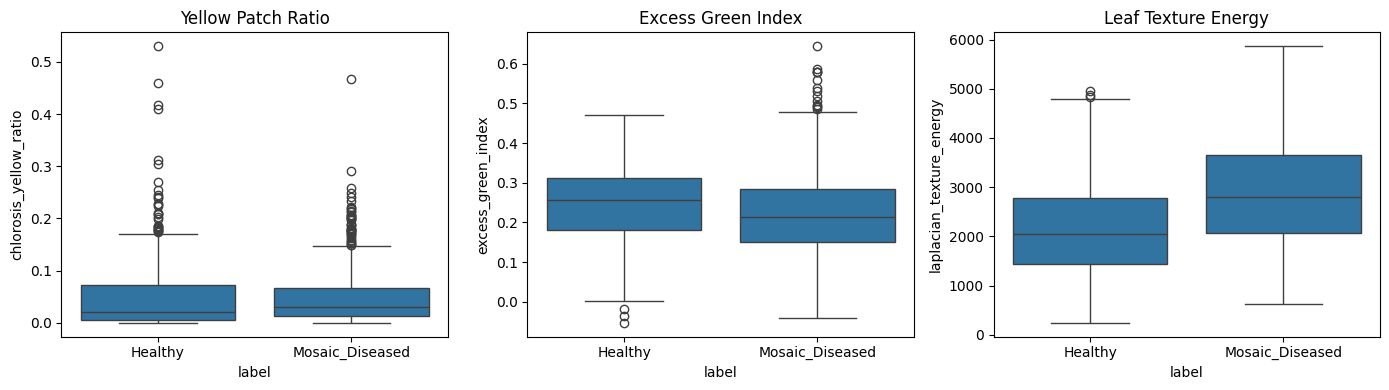

In [6]:
df_eda = pd.DataFrame(train_interp)
df_eda["label"] = [CLASSES[y] for y in train_labels]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(data=df_eda, x="label", y="chlorosis_yellow_ratio", ax=axes[0])
axes[0].set_title("Yellow Patch Ratio")

sns.boxplot(data=df_eda, x="label", y="excess_green_index", ax=axes[1])
axes[1].set_title("Excess Green Index")

sns.boxplot(data=df_eda, x="label", y="laplacian_texture_energy", ax=axes[2])
axes[2].set_title("Leaf Texture Energy")

plt.tight_layout()
plt.show()

## 2. Model Training and Hyperparameter Comparison

We compare three versions using Adam, L2 weight decay, dropout, learning rate decay, and early stopping.

In [7]:
def sigmoid(z):
    z = np.clip(z, -30.0, 30.0)
    return 1.0 / (1.0 + np.exp(-z))


def relu(z):
    return np.maximum(0.0, z)


def relu_grad(z):
    return (z > 0.0).astype(np.float32)


def compute_classification_metrics(y_true, y_prob, threshold=0.5):
    y_t = y_true.astype(np.int32).ravel()
    y_p = np.clip(y_prob.astype(np.float64).ravel(), 1e-7, 1.0 - 1e-7)
    y_pred = (y_p >= threshold).astype(np.int32)

    loss = float(-np.mean(y_t * np.log(y_p) + (1 - y_t) * np.log(1 - y_p)))

    tp = int(np.sum((y_t == 1) & (y_pred == 1)))
    tn = int(np.sum((y_t == 0) & (y_pred == 0)))
    fp = int(np.sum((y_t == 0) & (y_pred == 1)))
    fn = int(np.sum((y_t == 1) & (y_pred == 0)))

    accuracy = (tp + tn) / max(len(y_t), 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = (2 * precision * recall) / max(precision + recall, 1e-9)

    order = np.argsort(-y_p)
    y_sorted = y_t[order]
    n_pos = np.sum(y_t == 1)
    n_neg = np.sum(y_t == 0)

    if n_pos == 0 or n_neg == 0:
        roc_auc = 0.5
    else:
        tps = np.concatenate([[0.0], np.cumsum(y_sorted == 1) / n_pos])
        fps = np.concatenate([[0.0], np.cumsum(y_sorted == 0) / n_neg])
        if hasattr(np, "trapezoid"):
            roc_auc = float(np.trapezoid(tps, fps))
        else:
            roc_auc = float(np.trapz(tps, fps))

    return {
        "accuracy": round(float(accuracy), 4),
        "loss": round(float(loss), 4),
        "precision": round(float(precision), 4),
        "recall": round(float(recall), 4),
        "f1_score": round(float(f1), 4),
        "roc_auc": round(float(roc_auc), 4),
        "confusion_matrix": [[tn, fp], [fn, tp]],
    }


class CassavaNeuralClassifier:
    def __init__(
        self,
        input_dim,
        hidden_dims=(128, 64),
        learning_rate=1e-3,
        l2_lambda=1e-3,
        dropout_rates=(0.30, 0.20),
        seed=101,
    ):
        self.input_dim = input_dim
        self.hidden_dims = hidden_dims
        self.learning_rate = learning_rate
        self.l2_lambda = l2_lambda
        self.dropout_rates = dropout_rates
        self.seed = seed
        self.scaler = FeatureScaler()
        self.version = "v1.0.0"
        self.history = {}
        self.params = {}
        self._init_weights()

    def _init_weights(self):
        rng = np.random.default_rng(self.seed)
        h1, h2 = self.hidden_dims
        self.params = {
            "W1": rng.normal(0, np.sqrt(2.0 / self.input_dim), (self.input_dim, h1)).astype(np.float32),
            "b1": np.zeros((1, h1), dtype=np.float32),
            "W2": rng.normal(0, np.sqrt(2.0 / h1), (h1, h2)).astype(np.float32),
            "b2": np.zeros((1, h2), dtype=np.float32),
            "W3": rng.normal(0, np.sqrt(2.0 / h2), (h2, 1)).astype(np.float32),
            "b3": np.zeros((1, 1), dtype=np.float32),
        }

    def _forward(self, X, training=False, rng=None):
        z1 = X @ self.params["W1"] + self.params["b1"]
        a1 = relu(z1)
        m1 = np.ones_like(a1)
        if training and self.dropout_rates[0] > 0:
            keep1 = 1.0 - self.dropout_rates[0]
            m1 = (rng.random(a1.shape) < keep1).astype(np.float32) / keep1
            a1 = a1 * m1

        z2 = a1 @ self.params["W2"] + self.params["b2"]
        a2 = relu(z2)
        m2 = np.ones_like(a2)
        if training and self.dropout_rates[1] > 0:
            keep2 = 1.0 - self.dropout_rates[1]
            m2 = (rng.random(a2.shape) < keep2).astype(np.float32) / keep2
            a2 = a2 * m2

        z3 = a2 @ self.params["W3"] + self.params["b3"]
        probs = sigmoid(z3)

        cache = {
            "z1": z1, "a1": a1, "m1": m1,
            "z2": z2, "a2": a2, "m2": m2,
            "probs": probs,
        }
        return probs, cache

    def fit(
        self,
        X_train,
        y_train,
        X_val=None,
        y_val=None,
        epochs=80,
        batch_size=32,
        patience=12,
        lr_decay=0.985,
        fit_scaler=True,
    ):
        rng = np.random.default_rng(self.seed)

        if X_val is None or y_val is None:
            idx = rng.permutation(len(X_train))
            split = max(1, int(0.8 * len(idx)))
            X_tr_raw, y_tr = X_train[idx[:split]], y_train[idx[:split]]
            X_va_raw, y_va = X_train[idx[split:]], y_train[idx[split:]]
        else:
            X_tr_raw, y_tr = X_train, y_train
            X_va_raw, y_va = X_val, y_val

        if fit_scaler:
            X_tr = self.scaler.fit_transform(X_tr_raw)
        else:
            X_tr = self.scaler.transform(X_tr_raw)
        X_va = self.scaler.transform(X_va_raw)

        y_tr_col = y_tr.reshape(-1, 1).astype(np.float32)
        y_va_col = y_va.reshape(-1, 1).astype(np.float32)

        m = {k: np.zeros_like(v) for k, v in self.params.items()}
        v = {k: np.zeros_like(v) for k, v in self.params.items()}
        beta1, beta2, eps = 0.9, 0.999, 1e-8
        step = 0

        best_val_loss = float("inf")
        best_params = {k: val.copy() for k, val in self.params.items()}
        wait = 0

        history = {
            "train_loss": [],
            "val_loss": [],
            "train_acc": [],
            "val_acc": [],
            "best_epoch": 0,
            "stopped_early": False,
        }

        for epoch in range(1, epochs + 1):
            perm = rng.permutation(len(X_tr))
            lr = self.learning_rate * (lr_decay ** (epoch - 1))

            for start in range(0, len(X_tr), batch_size):
                batch_idx = perm[start : start + batch_size]
                xb = X_tr[batch_idx]
                yb = y_tr_col[batch_idx]
                n_b = len(xb)

                probs, cache = self._forward(xb, training=True, rng=rng)

                dz3 = (probs - yb) / n_b
                dW3 = cache["a2"].T @ dz3 + self.l2_lambda * self.params["W3"]
                db3 = np.sum(dz3, axis=0, keepdims=True)

                da2 = dz3 @ self.params["W3"].T
                dz2 = da2 * cache["m2"] * relu_grad(cache["z2"])
                dW2 = cache["a1"].T @ dz2 + self.l2_lambda * self.params["W2"]
                db2 = np.sum(dz2, axis=0, keepdims=True)

                da1 = dz2 @ self.params["W2"].T
                dz1 = da1 * cache["m1"] * relu_grad(cache["z1"])
                dW1 = xb.T @ dz1 + self.l2_lambda * self.params["W1"]
                db1 = np.sum(dz1, axis=0, keepdims=True)

                grads = {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2, "W3": dW3, "b3": db3}
                step += 1

                for k in self.params:
                    m[k] = beta1 * m[k] + (1 - beta1) * grads[k]
                    v[k] = beta2 * v[k] + (1 - beta2) * (grads[k] ** 2)
                    m_hat = m[k] / (1 - beta1 ** step)
                    v_hat = v[k] / (1 - beta2 ** step)
                    self.params[k] -= lr * m_hat / (np.sqrt(v_hat) + eps)

            tr_probs, _ = self._forward(X_tr, training=False)
            va_probs, _ = self._forward(X_va, training=False)
            tr_m = compute_classification_metrics(y_tr_col, tr_probs)
            va_m = compute_classification_metrics(y_va_col, va_probs)

            history["train_loss"].append(tr_m["loss"])
            history["val_loss"].append(va_m["loss"])
            history["train_acc"].append(tr_m["accuracy"])
            history["val_acc"].append(va_m["accuracy"])

            if va_m["loss"] < best_val_loss - 1e-4:
                best_val_loss = va_m["loss"]
                best_params = {k: val.copy() for k, val in self.params.items()}
                history["best_epoch"] = epoch
                wait = 0
            else:
                wait += 1
                if wait >= patience:
                    history["stopped_early"] = True
                    break

        self.params = best_params
        self.history = history
        return history

    def predict_proba(self, X_raw):
        X_scaled = self.scaler.transform(X_raw)
        probs, _ = self._forward(X_scaled, training=False)
        return probs.ravel()

    def evaluate(self, X_raw, y_true):
        probs = self.predict_proba(X_raw)
        return compute_classification_metrics(y_true, probs)

    def save(self, path):
        out_path = Path(path)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        with open(out_path, "wb") as f:
            pickle.dump(self, f)
        return out_path

    @classmethod
    def load(cls, path):
        with open(path, "rb") as f:
            return pickle.load(f)


def retrain_from_pretrained(pretrained_path, X_new, y_new, epochs=35, fine_tune_lr=3e-4, save_path=None):
    model = CassavaNeuralClassifier.load(pretrained_path)
    model.learning_rate = fine_tune_lr
    history = model.fit(X_new, y_new, epochs=epochs, batch_size=16, patience=8, fit_scaler=False)

    minor = int(model.version.lstrip("v").split(".")[1]) + 1
    model.version = f"v1.{minor}.0"

    target = Path(save_path) if save_path else Path(pretrained_path)
    model.save(target)
    return model, {
        "version": model.version,
        "epochs_ran": len(history["train_loss"]),
        "best_epoch": history["best_epoch"],
        "stopped_early": history["stopped_early"],
        "metrics": model.evaluate(X_new, y_new),
    }

## Train And Compare Versions

In [8]:
configs = [
    {"name": "Baseline (lr=1e-3, L2=0)", "lr": 1e-3, "l2": 0.0, "dropout": (0.0, 0.0)},
    {"name": "Regularized (lr=1e-3, L2=1e-3, Drop=0.3/0.2)", "lr": 1e-3, "l2": 1e-3, "dropout": (0.3, 0.2)},
    {"name": "Tuned (lr=8e-4, L2=2e-3, Drop=0.3/0.2)", "lr": 8e-4, "l2": 2e-3, "dropout": (0.3, 0.2)},
]

results = []
best_model = None
best_f1 = -1.0

for cfg in configs:
    m = CassavaNeuralClassifier(
        input_dim=X_train.shape[1],
        hidden_dims=(128, 64),
        learning_rate=cfg["lr"],
        l2_lambda=cfg["l2"],
        dropout_rates=cfg["dropout"],
        seed=101,
    )
    hist = m.fit(X_train, y_train, epochs=80, batch_size=32, patience=12)
    ev = m.evaluate(X_test, y_test)
    results.append({
        "Configuration": cfg["name"],
        "Best Epoch": hist["best_epoch"],
        "Accuracy": ev["accuracy"],
        "Loss": ev["loss"],
        "F1": ev["f1_score"],
        "ROC-AUC": ev["roc_auc"],
    })
    if ev["f1_score"] >= best_f1:
        best_f1 = ev["f1_score"]
        best_model = m

model_path = MODELS_DIR / "cassava_classifier.pkl"
best_model.save(model_path)
pd.DataFrame(results)

,Configuration,Best Epoch,Accuracy,Loss,F1,ROC-AUC
0,"Baseline (lr=1e-3, L2=0)",2,0.6277,0.7128,0.6906,0.6832
1,"Regularized (lr=1e-3, L2=1e-3, Drop=0.3/0.2)",4,0.6320,0.7144,0.6975,0.6914
2,"Tuned (lr=8e-4, L2=2e-3, Drop=0.3/0.2)",7,0.6234,0.7702,0.6904,0.6932


## 3. Evaluation Metrics, Learning Curves, and Confusion Matrix

{
  "accuracy": 0.632,
  "loss": 0.7144,
  "precision": 0.6282,
  "recall": 0.784,
  "f1_score": 0.6975,
  "roc_auc": 0.6914,
  "confusion_matrix": [
    [
      48,
      58
    ],
    [
      27,
      98
    ]
  ]
}


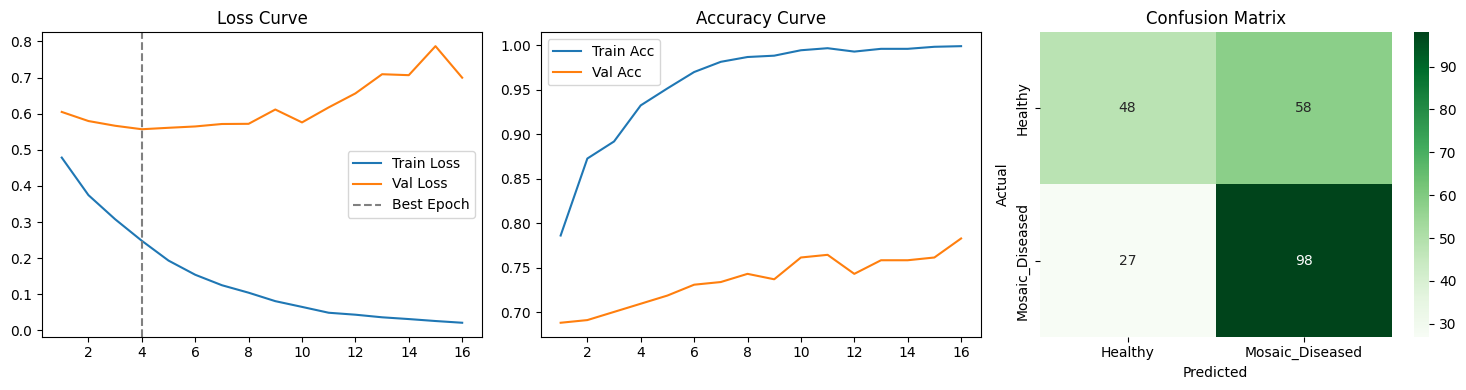

In [10]:
final_metrics = best_model.evaluate(X_test, y_test)
print(json.dumps(final_metrics, indent=2))

with open(MODELS_DIR / "baseline_metrics.json", "w") as f:
    json.dump({"tuning": results, "final_test_metrics": final_metrics}, f, indent=2)

epochs_axis = range(1, len(best_model.history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(epochs_axis, best_model.history["train_loss"], label="Train Loss")
axes[0].plot(epochs_axis, best_model.history["val_loss"], label="Val Loss")
axes[0].axvline(best_model.history["best_epoch"], color="gray", linestyle="--", label="Best Epoch")
axes[0].set_title("Loss Curve")
axes[0].legend()

axes[1].plot(epochs_axis, best_model.history["train_acc"], label="Train Acc")
axes[1].plot(epochs_axis, best_model.history["val_acc"], label="Val Acc")
axes[1].set_title("Accuracy Curve")
axes[1].legend()

cm = np.array(final_metrics["confusion_matrix"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[2])
axes[2].set_title("Confusion Matrix")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 4. Test Single Image Prediction

In [11]:
def predict_file(model, file_path):
    img_rgb = load_image_from_path(file_path)
    feats_vec = extract_feature_vector(img_rgb).reshape(1, -1)
    prob_diseased = float(model.predict_proba(feats_vec)[0])
    pred_idx = int(prob_diseased >= 0.5)
    confidence = prob_diseased if pred_idx == 1 else (1.0 - prob_diseased)
    return {
        "predicted_class": CLASSES[pred_idx],
        "confidence": round(confidence, 4),
        "model_version": model.version,
    }


loaded_model = CassavaNeuralClassifier.load(model_path)
print("Healthy sample:", predict_file(loaded_model, test_paths[0]))
print("Mosaic_Diseased sample:", predict_file(loaded_model, test_paths[-1]))

retrained_model, retrain_info = retrain_from_pretrained(
    model_path,
    X_test[:20],
    y_test[:20],
    epochs=10,
    save_path=MODELS_DIR / "cassava_classifier_retrained.pkl",
)
print("Retrain info:", retrain_info)

Healthy sample: {'predicted_class': 'Healthy', 'confidence': 0.674, 'model_version': 'v1.0.0'}
Mosaic_Diseased sample: {'predicted_class': 'Mosaic_Diseased', 'confidence': 0.9786, 'model_version': 'v1.0.0'}
Retrain info: {'version': 'v1.1.0', 'epochs_ran': 10, 'best_epoch': 10, 'stopped_early': False, 'metrics': {'accuracy': 0.95, 'loss': 0.229, 'precision': 0.0, 'recall': 0.0, 'f1_score': 0.0, 'roc_auc': 0.5, 'confusion_matrix': [[19, 1], [0, 0]]}}
